# Comparison: 9/11 vs. Financial Crisis vs. COVID-19

The comparable plots from `results 911`, `Financial_crisis_dataresults` and `results_covid`, placed side by side.
Settings, calculations and layout are the same as in the original notebooks.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

In [5]:
# Settings per event (taken from the three notebooks)
events = {
    '9/11': dict(
        event_name='9/11',
        event_date=pd.Timestamp('2001-09-01'),
        shock_start=pd.Timestamp('2001-09-01'),
        shock_end=pd.Timestamp('2001-09-01'),
        base_start=pd.Timestamp('1996-09-01'),     # five historical years
        plot_start=pd.Timestamp('1996-09-01'),
        plot_end=pd.Timestamp('2006-09-01'),
        base_label='Sep 1996 - Aug 2001',
        span_label=None,                           # no grey period, only the dashed line
        yoy_ylim=None,
        dev_ylim=None,
        model='anchored',
        forecast_guard=False,                      # 9/11 notebook also forecasts the first months (data starts in 1992)
        base_year=2000,
        years=list(range(1996, 2007)),
        partial_last_year=False,                   # 9/11 notebook uses the full year 2006
        decimals=1,
        source='excel',
        no_event='9/11',
    ),
    'Financial Crisis': dict(
        event_name='Financial Crisis',
        event_date=pd.Timestamp('2008-09-01'),
        shock_start=pd.Timestamp('2008-01-01'),
        shock_end=pd.Timestamp('2010-01-01'),
        base_start=pd.Timestamp('2004-01-01'),
        plot_start=pd.Timestamp('2004-01-01'),
        plot_end=pd.Timestamp('2015-01-01'),
        base_label='2004-2007',
        span_label='Financial Crisis',
        yoy_ylim=(-20, 50),
        dev_ylim=(-25, 50),
        model='rolling',
        base_year=2007,
        years=list(range(2004, 2016)),
        partial_last_year=True,
        decimals=0,
        source='csv',
        no_event='financial crisis',
    ),
    'COVID-19': dict(
        event_name='COVID-19',
        event_date=pd.Timestamp('2020-03-01'),
        shock_start=pd.Timestamp('2020-01-01'),
        shock_end=pd.Timestamp('2022-12-01'),
        base_start=pd.Timestamp('2015-01-01'),
        plot_start=pd.Timestamp('2015-01-01'),
        plot_end=None,                             # newest month in the data (set below)
        base_label='2015-2019',
        span_label='COVID-19 (2020-2022)',
        yoy_ylim=(-110, 600),
        dev_ylim=None,
        model='anchored',
        forecast_guard=True,
        base_year=2019,
        years=None,                                # 2015 up to the newest year (set below)
        partial_last_year=True,
        decimals=0,
        source='csv',
        no_event='coronavirus',
    ),
}

In [6]:
# Load data
# The CSV starts in 1999, so 9/11 (baseline from 1996) uses the Excel file, just like the 9/11 notebook
def load_excel(path):
    df = pd.read_excel(path, header=[7, 8])
    data = df[
        [
            ('Unnamed: 0_level_0', 'Year'),
            ('Unnamed: 1_level_0', 'Month'),
            ('Passengers', 'Total*'),
            ('Air Transport Movements', 'Total')
        ]
    ].copy()
    data.columns = ['Year', 'Month', 'Passengers', 'Flights']
    data['Year'] = data['Year'].ffill()

    months = ['January', 'February', 'March', 'April', 'May', 'June',
              'July', 'August', 'September', 'October', 'November', 'December']
    data = data[data['Month'].isin(months)].copy()

    data['Year'] = pd.to_numeric(data['Year'], errors='coerce')
    data = data.dropna(subset=['Year'])
    data['Year'] = data['Year'].astype(int)
    data['Date'] = pd.to_datetime(data['Year'].astype(str) + ' ' + data['Month'], format='%Y %B')
    data = data.sort_values('Date').reset_index(drop=True)
    data['Month_Num'] = data['Date'].dt.month
    data['Passengers'] = data['Passengers'].astype(float)
    data['Flights'] = data['Flights'].astype(float)
    return data[['Date', 'Passengers', 'Flights', 'Year', 'Month_Num']]


def load_csv(path):
    data = pd.read_csv(path, parse_dates=['Date'])
    data['Year'] = data['Date'].dt.year
    data['Month_Num'] = data['Date'].dt.month
    return data


sources = {
    'excel': load_excel('covid_data/Monthly_traffic_data_1992-current.xlsx'),
    'csv': load_csv(Path('covid_data') / 'schiphol_maandelijks.csv'),
}

# COVID: plot up to the newest month in the data
newest = sources['csv']['Date'].max()
events['COVID-19']['plot_end'] = newest
events['COVID-19']['years'] = list(range(2015, newest.year + 1))

for name, ev in events.items():
    d = sources[ev['source']]
    print(name.ljust(17), ev['source'], d['Date'].min().date(), '-', d['Date'].max().date())

ImportError: `Import openpyxl` failed.  Use pip or conda to install the openpyxl package.

In [ ]:
# Baseline, index, year-on-year and prediction model per event

def expected_anchored(data, ev, year, month, n_growth_years=5):
    # 9/11 and COVID notebooks: grow from the last normal year with the average growth of the 5 years before
    last_normal_year = ev['shock_start'].year - 1
    anchor = min(year - 1, last_normal_year)
    if ev['forecast_guard'] and anchor < ev['base_start'].year:
        return np.nan
    growth_rows = data[(data['Month_Num'] == month) & (data['Year'] > anchor - n_growth_years) & (data['Year'] <= anchor)]
    avg_growth = growth_rows['YoY'].mean() / 100
    anchor_value = data[(data['Year'] == anchor) & (data['Month_Num'] == month)]['Passengers'].values[0]
    return anchor_value * (1 + avg_growth) ** (year - anchor)


def expected_rolling(data, year, month):
    # Financial crisis notebook: previous year times the average growth of the 5 years before
    train = data[(data['Year'] >= year - 5) & (data['Year'] <= year - 1) & (data['Month_Num'] == month)]
    avg_growth = train['YoY'].mean() / 100
    prev = data[(data['Year'] == year - 1) & (data['Month_Num'] == month)]
    if prev.empty:
        return np.nan
    return prev['Passengers'].values[0] * (1 + avg_growth)


for name, ev in events.items():
    data = sources[ev['source']].copy()

    # the years before the event
    before = data[(data['Date'] >= ev['base_start']) & (data['Date'] < ev['shock_start'])]
    base_pax = before.groupby('Month_Num')['Passengers'].mean()
    base_flights = before.groupby('Month_Num')['Flights'].mean()

    # index figures: 100 = same month in the baseline
    data['Index_Pax'] = data['Passengers'] / data['Month_Num'].map(base_pax) * 100
    data['Index_Flights'] = data['Flights'] / data['Month_Num'].map(base_flights) * 100

    # year-on-year change in % (same month, one year earlier)
    data['YoY'] = data.groupby('Month_Num')['Passengers'].pct_change() * 100

    window = data[(data['Date'] >= ev['plot_start']) & (data['Date'] <= ev['plot_end'])].copy().reset_index(drop=True)

    predicted = []
    for i, row in window.iterrows():
        if ev['model'] == 'anchored':
            predicted.append(expected_anchored(data, ev, row['Year'], row['Month_Num']))
        else:
            predicted.append(expected_rolling(data, row['Year'], row['Month_Num']))
    window['Predicted'] = predicted
    window['Deviation'] = (window['Passengers'] - window['Predicted']) / window['Predicted'] * 100

    ev['data'] = data
    ev['window'] = window

    low = window.loc[window['Index_Pax'].idxmin()]
    print(name.ljust(17), 'lowest index:', low['Date'].strftime('%B %Y'), round(low['Index_Pax'], 1))

9/11              lowest index: November 1996 80.8
Financial Crisis  lowest index: April 2010 81.6
COVID-19          lowest index: April 2020 2.3


In [ ]:
# Consistent layout for all plots (same style as the separate notebooks, now 3 side by side)
colors = {'main': '#1f4e79', 'second': '#e07b39', 'good': '#2e8b57', 'bad': '#c0392b', 'grey': '#8c8c8c'}

def make_figure(title, subtitles, ylabel, source='Schiphol, CBS'):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
    fig.suptitle(title, x=0.01, ha='left', fontsize=16, fontweight='bold')
    for ax, (name, ev) in zip(axes, events.items()):
        ax.set_title(name, loc='left', fontsize=14, fontweight='bold', pad=28)
        ax.text(0, 1.03, subtitles[name], transform=ax.transAxes, fontsize=10, color='#555555')
        ax.set_ylabel(ylabel)
        ax.grid(axis='y', color='#e6e6e6')
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    fig.text(0.01, 0.01, 'Source: ' + source, fontsize=8, color='#888888')
    return fig, axes

def mark_event(ax, ev):
    # grey area for the event period and dashed line at the event itself
    if ev['span_label'] is not None:
        ax.axvspan(ev['shock_start'], ev['shock_end'], color='#eeeeee', zorder=0)
        ax.text(ev['shock_start'], 0.97, ' ' + ev['span_label'], transform=ax.get_xaxis_transform(),
                va='top', fontsize=9, color='#555555',
                bbox=dict(facecolor='#eeeeee', edgecolor='none', pad=1))
    ax.axvline(ev['event_date'], linestyle='--', color=colors['grey'], linewidth=1)
    ax.set_xlim(ev['plot_start'], ev['plot_end'])
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

def finish(axes, legend=True):
    if legend:
        for ax in axes:
            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
    plt.tight_layout(rect=(0, 0.02, 1, 1))
    plt.show()

## Plot 1: Passengers per month

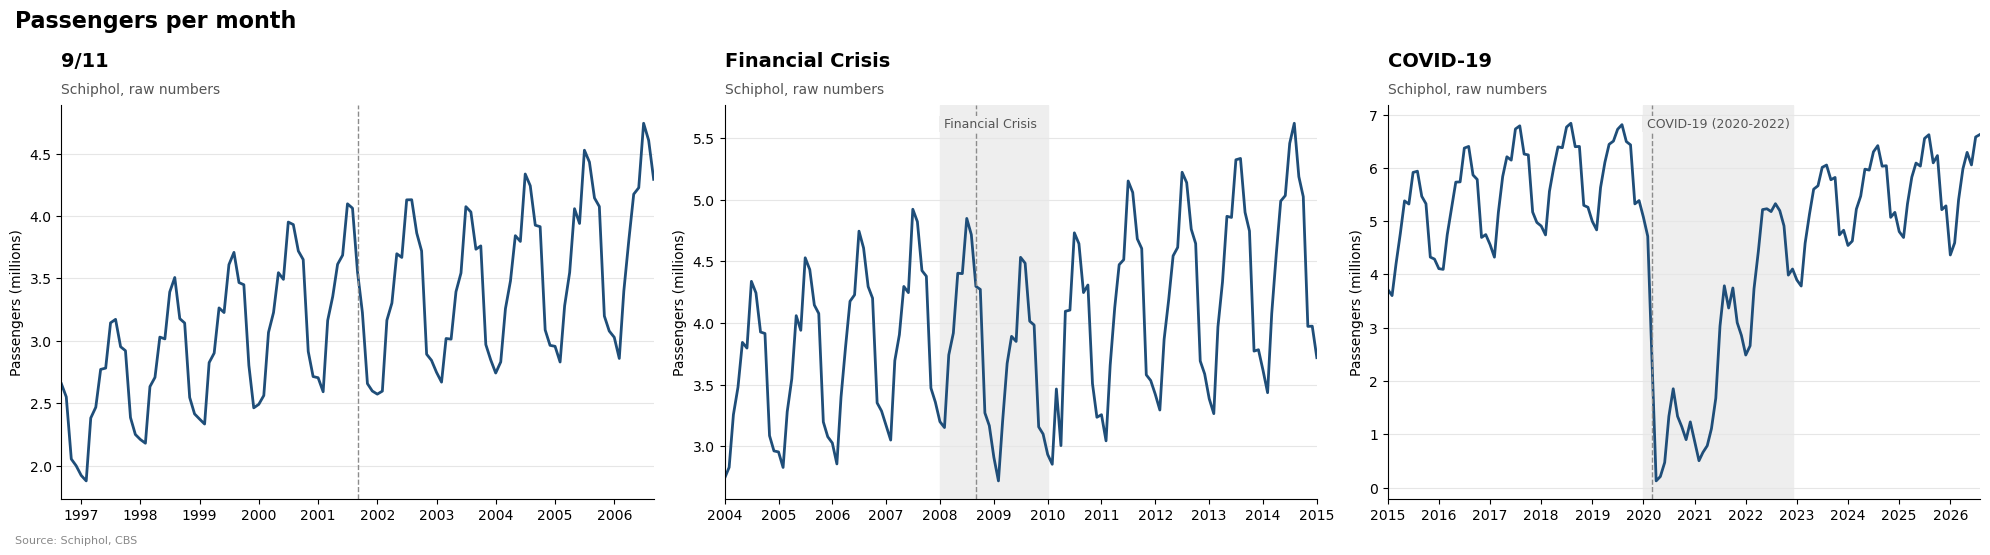

In [ ]:
fig, axes = make_figure('Passengers per month', {n: 'Schiphol, raw numbers' for n in events}, 'Passengers (millions)')

for ax, ev in zip(axes, events.values()):
    w = ev['window']
    ax.plot(w['Date'], w['Passengers'] / 1e6, color=colors['main'], linewidth=2, label='Passengers')
    mark_event(ax, ev)
finish(axes, legend=False)

## Plot 2: Passengers compared to baseline

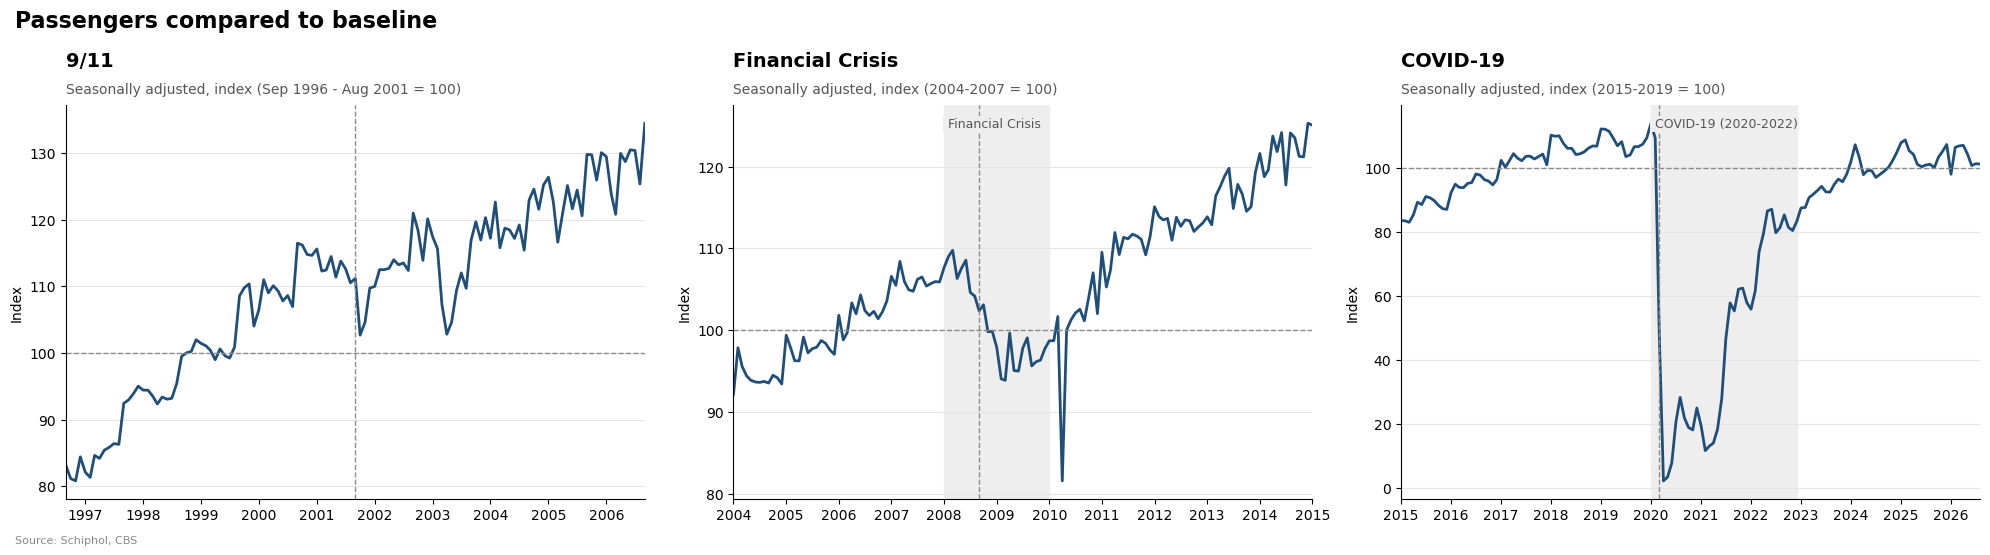

In [ ]:
fig, axes = make_figure('Passengers compared to baseline',
                        {n: 'Seasonally adjusted, index (' + ev['base_label'] + ' = 100)' for n, ev in events.items()},
                        'Index')

for ax, ev in zip(axes, events.values()):
    w = ev['window']
    ax.plot(w['Date'], w['Index_Pax'], color=colors['main'], linewidth=2, label='Passengers (index)')
    ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
    mark_event(ax, ev)
finish(axes, legend=False)

## Plot 3: Year-over-Year change in passengers

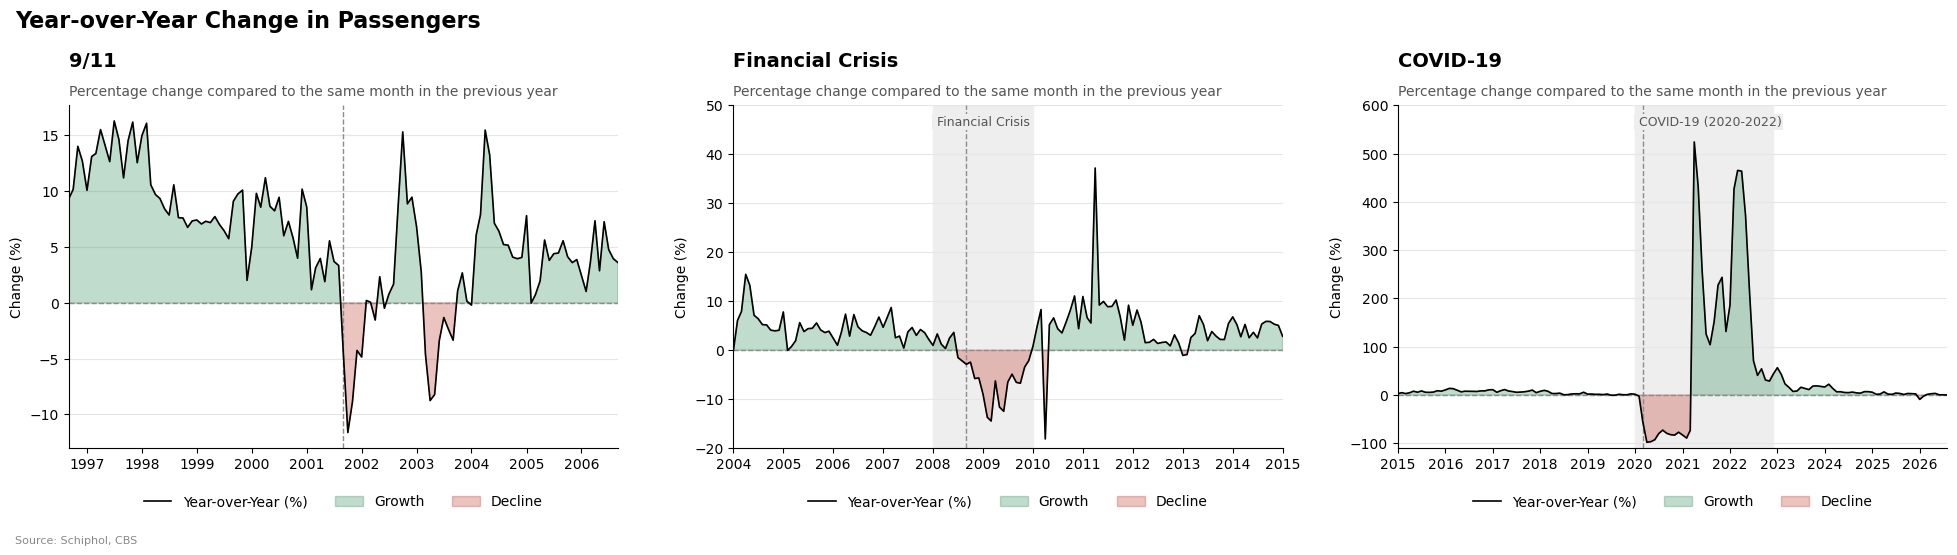

In [ ]:
fig, axes = make_figure('Year-over-Year Change in Passengers',
                        {n: 'Percentage change compared to the same month in the previous year' for n in events},
                        'Change (%)')

for ax, ev in zip(axes, events.values()):
    dates = ev['window']['Date'].values
    yoy = ev['window']['YoY'].values
    ax.plot(dates, yoy, color='black', linewidth=1.2, label='Year-over-Year (%)', zorder=3)
    ax.fill_between(dates, yoy, 0, where=(yoy >= 0), color=colors['good'], alpha=0.3, interpolate=True, label='Growth')
    ax.fill_between(dates, yoy, 0, where=(yoy < 0), color=colors['bad'], alpha=0.3, interpolate=True, label='Decline')
    ax.axhline(0, linestyle='--', color=colors['grey'], linewidth=1)
    if ev['yoy_ylim'] is not None:
        ax.set_ylim(*ev['yoy_ylim'])
    mark_event(ax, ev)
finish(axes)

## Plot 4: Passengers versus flight movements

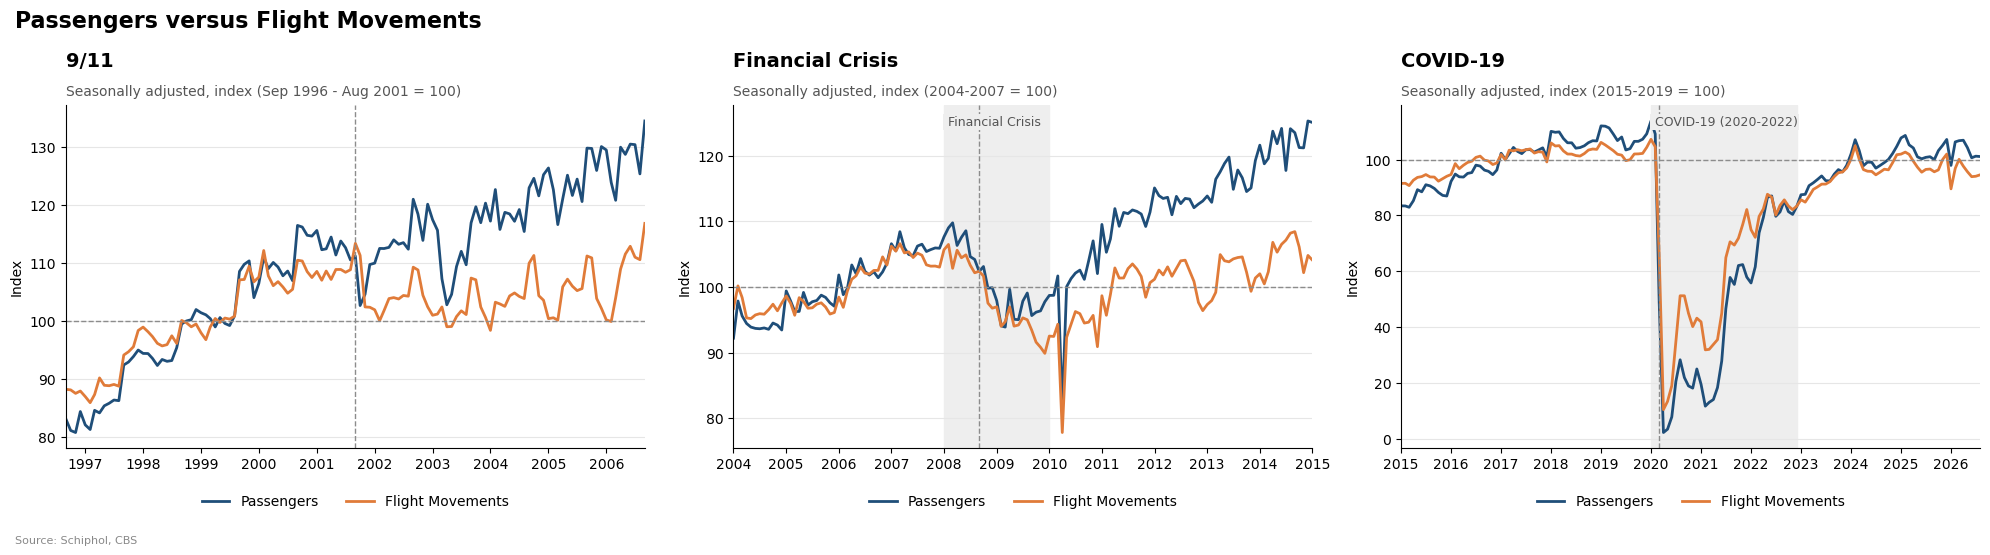

In [ ]:
fig, axes = make_figure('Passengers versus Flight Movements',
                        {n: 'Seasonally adjusted, index (' + ev['base_label'] + ' = 100)' for n, ev in events.items()},
                        'Index')

for ax, ev in zip(axes, events.values()):
    w = ev['window']
    ax.plot(w['Date'], w['Index_Pax'], color=colors['main'], linewidth=2, label='Passengers')
    ax.plot(w['Date'], w['Index_Flights'], color=colors['second'], linewidth=2, label='Flight Movements')
    ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
    mark_event(ax, ev)
finish(axes)

## Plot 5: Deviation from the forecast model

9/11 and COVID-19 use the forecast from the last normal year; the financial crisis uses the rolling 5-year growth model from its own notebook.

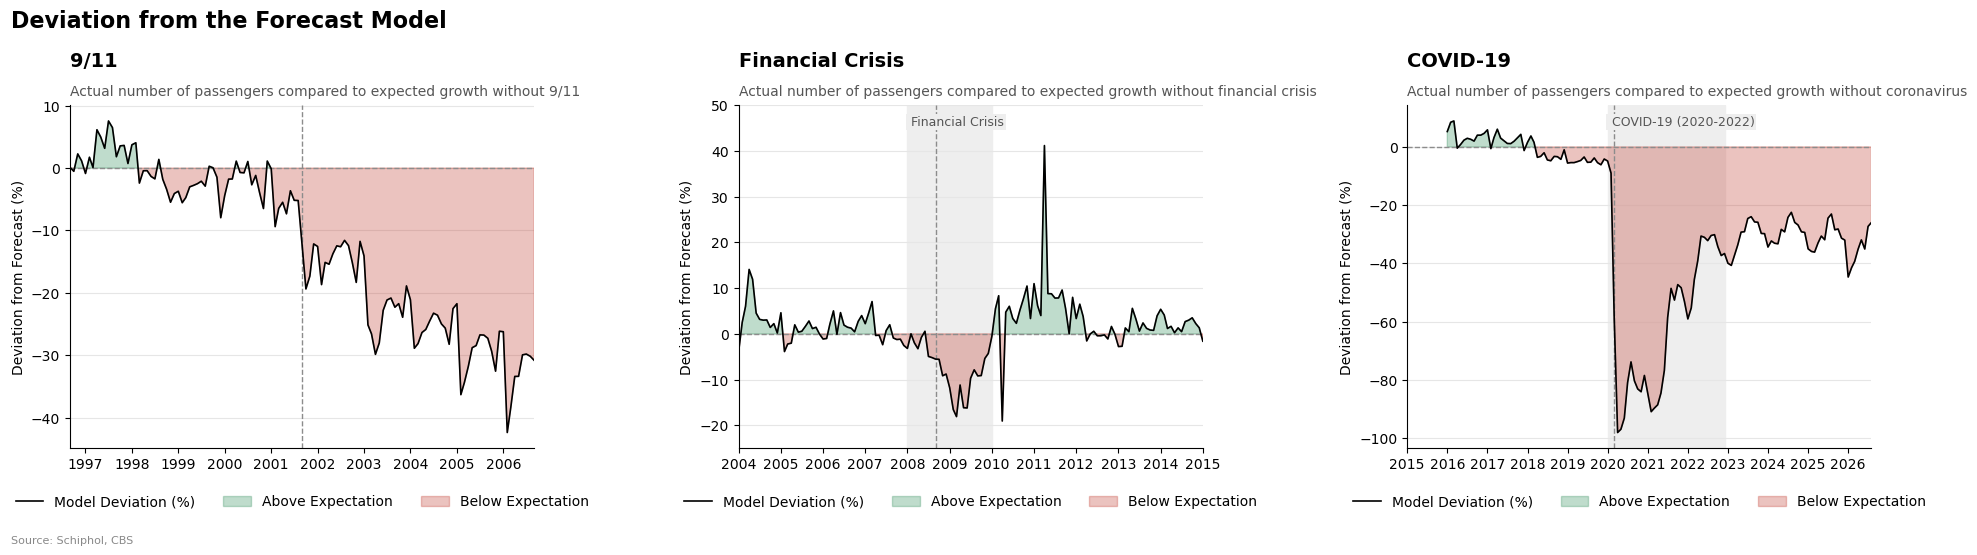

In [ ]:
fig, axes = make_figure('Deviation from the Forecast Model',
                        {n: 'Actual number of passengers compared to expected growth without ' + ev['no_event'] for n, ev in events.items()},
                        'Deviation from Forecast (%)')

for ax, ev in zip(axes, events.values()):
    dates = ev['window']['Date'].values
    devs = ev['window']['Deviation'].values
    ax.plot(dates, devs, color='black', linewidth=1.2, label='Model Deviation (%)', zorder=3)
    ax.fill_between(dates, devs, 0, where=(devs >= 0), color=colors['good'], alpha=0.3, interpolate=True, label='Above Expectation')
    ax.fill_between(dates, devs, 0, where=(devs < 0), color=colors['bad'], alpha=0.3, interpolate=True, label='Below Expectation')
    ax.axhline(0, linestyle='--', color=colors['grey'], linewidth=1)
    if ev['dev_ylim'] is not None:
        ax.set_ylim(*ev['dev_ylim'])
    mark_event(ax, ev)
finish(axes)

## Plot 6: Yearly total passengers

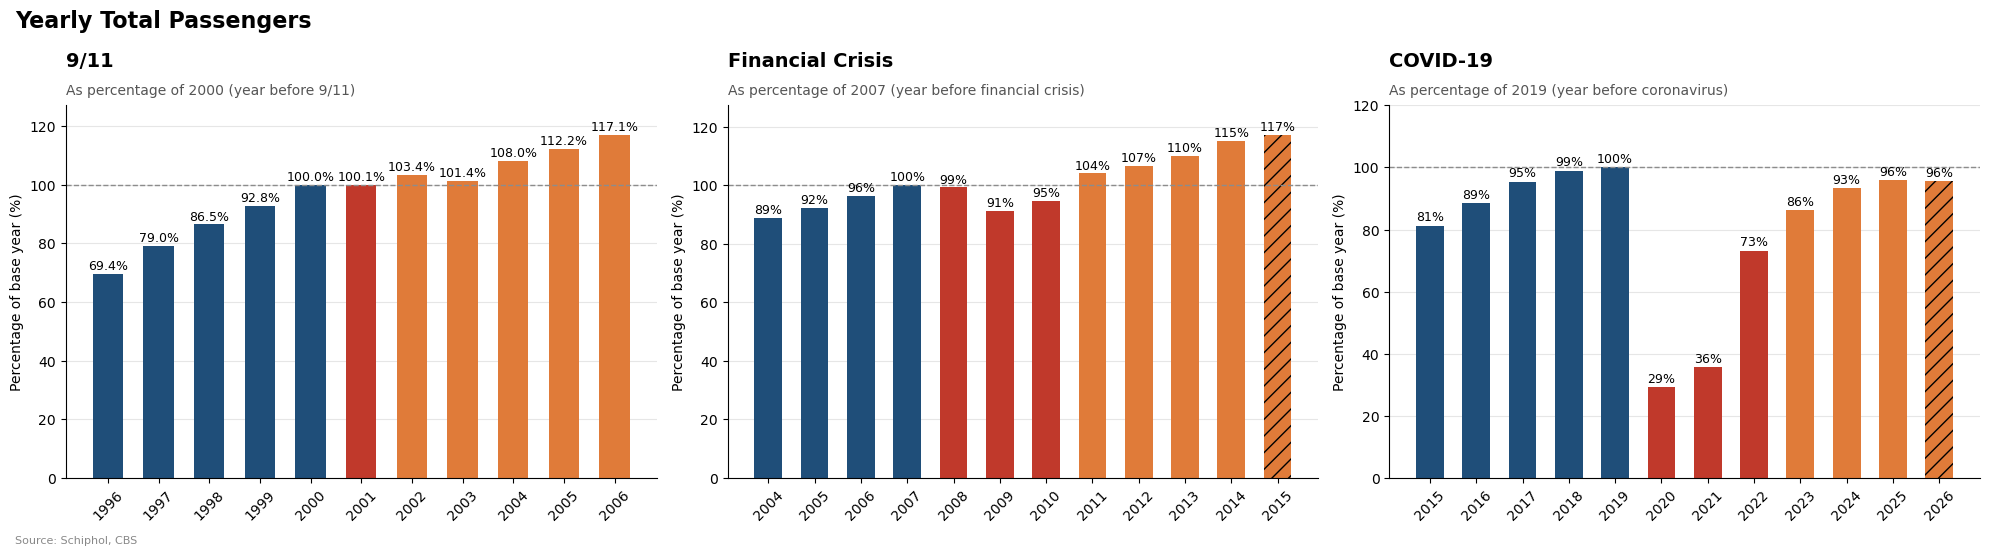

In [ ]:
fig, axes = make_figure('Yearly Total Passengers',
                        {n: 'As percentage of ' + str(ev['base_year']) + ' (year before ' + ev['no_event'] + ')' for n, ev in events.items()},
                        'Percentage of base year (%)')

for ax, ev in zip(axes, events.values()):
    data = ev['data']
    base_year = ev['base_year']
    years = ev['years']
    last_year = years[-1]
    last_month = ev['plot_end'].month
    partial = ev['partial_last_year'] and last_month < 12

    totals = data.groupby('Year')['Passengers'].sum()
    percentages = []
    for y in years:
        if y == last_year and partial:
            # incomplete year: only the months we have, compared to the same months in the base year
            this_year = data[(data['Year'] == y) & (data['Month_Num'] <= last_month)]['Passengers'].sum()
            same_base = data[(data['Year'] == base_year) & (data['Month_Num'] <= last_month)]['Passengers'].sum()
            percentages.append(this_year / same_base * 100)
        else:
            percentages.append(totals[y] / totals[base_year] * 100)

    bar_colors = []
    for y in years:
        if y < ev['shock_start'].year:
            bar_colors.append(colors['main'])
        elif y <= ev['shock_end'].year:
            bar_colors.append(colors['bad'])
        else:
            bar_colors.append(colors['second'])

    bars = ax.bar(years, percentages, color=bar_colors, width=0.6)
    if partial:
        bars[-1].set_hatch('//')       # incomplete year
    for y, p in zip(years, percentages):
        ax.text(y, p + 1.5, f"{p:.{ev['decimals']}f}%", ha='center', fontsize=9)
    ax.axhline(100, linestyle='--', color=colors['grey'], linewidth=1)
    ax.set_ylim(0, max(120, max(percentages) + 10))
    ax.set_xticks(years)
    ax.tick_params(axis='x', labelrotation=45 if len(years) > 9 else 0)
finish(axes, legend=False)

# Plot 7: Comparison summary table

,9/11,Financial Crisis,COVID-19
Type of disruption,Security-related,Economic,Health-related
Largest monthly YoY decline,-11.6%,-14.5%,-97.9%
Month of largest decline,October 2001,March 2009,April 2020
Passenger change during first 12 months,-2.4%,-7.8%,-82.6%
Months with negative YoY growth,7 of 12,12 of 12,12 of 12


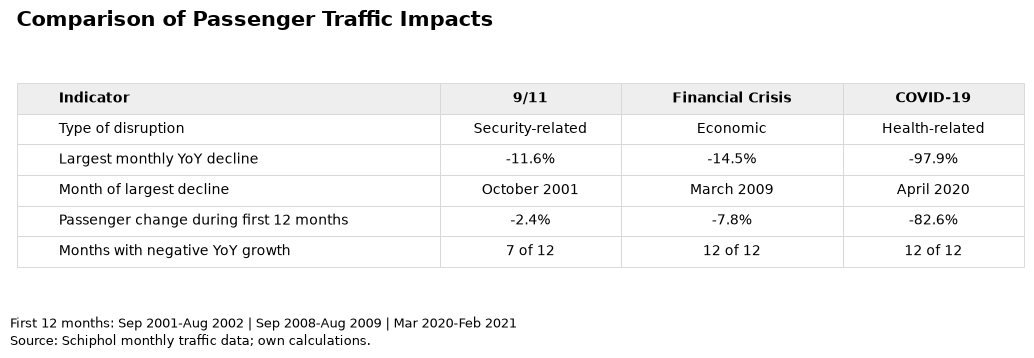

Saved: Comparison figures\Comparison summary table.png


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load Schiphol data
data = pd.read_csv(
    "covid_data/schiphol_maandelijks.csv",
    parse_dates=["Date"]
).sort_values("Date").copy()

# Calculate year-on-year changes
data["Month"] = data["Date"].dt.month
data["PreviousYear"] = data.groupby("Month")["Passengers"].shift(1)
data["YoY"] = (
    (data["Passengers"] / data["PreviousYear"] - 1) * 100
)

# Event starting dates and disruption types
events = {
    "9/11": ("2001-09-01", "Security-related"),
    "Financial Crisis": ("2008-09-01", "Economic"),
    "COVID-19": ("2020-03-01", "Health-related")
}

results = {}

for event, (date, event_type) in events.items():
    start = pd.Timestamp(date)
    end = start + pd.DateOffset(months=12)

    period = data[
        (data["Date"] >= start) &
        (data["Date"] < end)
    ]

    if len(period) != 12 or period["PreviousYear"].isna().any():
        raise ValueError(f"Incomplete data for {event}")

    lowest = period.loc[period["YoY"].idxmin()]

    passenger_change = (
        period["Passengers"].sum() /
        period["PreviousYear"].sum() - 1
    ) * 100

    results[event] = {
        "Type of disruption": event_type,
        "Largest monthly YoY decline": f'{lowest["YoY"]:.1f}%',
        "Month of largest decline": lowest["Date"].strftime("%B %Y"),
        "Passenger change during first 12 months": f"{passenger_change:.1f}%",
        "Months with negative YoY growth": f'{(period["YoY"] < 0).sum()} of 12'
    }

# Create summary table
summary = pd.DataFrame(results)

display(summary)

# Create a simple table figure
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.axis("off")

ax.set_title(
    "Comparison of Passenger Traffic Impacts",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=18
)

table = ax.table(
    cellText=summary.reset_index().values,
    colLabels=["Indicator", "9/11", "Financial Crisis", "COVID-19"],
    cellLoc="center",
    colWidths=[0.42, 0.18, 0.22, 0.18],
    bbox=[0, 0.20, 1, 0.68]
)

table.auto_set_font_size(False)
table.set_fontsize(10)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#D5D5D5")
    cell.set_linewidth(0.6)

    if row == 0:
        cell.set_facecolor("#EEEEEE")
        cell.set_text_props(weight="bold")

    if col == 0:
        cell.set_text_props(ha="left")

fig.text(
    0.12, 0.09,
    "First 12 months: Sep 2001-Aug 2002 | Sep 2008-Aug 2009 | Mar 2020-Feb 2021",
    fontsize=9
)

fig.text(
    0.12, 0.04,
    "Source: Schiphol monthly traffic data; own calculations.",
    fontsize=9
)

# Save figure
output = Path("Comparison figures/Comparison summary table.png")
output.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Saved:", output)
